### Homework 01
Igor Di Tota

The following three cells are taken from the lecture notebook and are used to load the data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Data set to be used for the homework
hwlink = "https://www.fuw.edu.pl/~zarnecki/SAED/OECD_Poland_filtered.csv"

# Reading from the web (relevant columns only)
hw= pd.read_csv(hwlink, encoding='latin-1', sep=",", usecols=['SEX','Sex','AGE','Age','TIME_PERIOD','OBS_VALUE'])  # Columns are counted from 0 (!)

print(hw)

     SEX     Sex     AGE                  Age  TIME_PERIOD  OBS_VALUE
0      F  Female  Y_GE50     50 years or over         1960  3379322.0
1      F  Female  Y_GE50     50 years or over         1961  3403900.0
2      F  Female  Y_GE50     50 years or over         1962  3502400.0
3      F  Female  Y_GE50     50 years or over         1963  3625100.0
4      F  Female  Y_GE50     50 years or over         1964  3728901.0
...   ..     ...     ...                  ...          ...        ...
3643   F  Female  Y_GE50     50 years or over         2025  8215716.0
3644   F  Female   Y_LE4      4 years or less         2025   707100.0
3645   F  Female  Y55T59  From 55 to 59 years         2025  1115886.0
3646   F  Female  Y30T34  From 30 to 34 years         2025  1198754.0
3647   F  Female  Y15T19  From 15 to 19 years         2025   987098.0

[3648 rows x 6 columns]


In [2]:
# List of age categories in the data set

AgeList = hw.drop_duplicates(subset='AGE',ignore_index=True)

ncat = AgeList.shape[0]

print(ncat," age categories found in the data base:")

for icat in range(ncat):
    print("    {:6s}  =>  {:s}".format(AgeList.at[icat,"AGE"],AgeList.at[icat,"Age"]))

24  age categories found in the data base:
    Y_GE50  =>  50 years or over
    Y80T84  =>  From 80 to 84 years
    Y25T29  =>  From 25 to 29 years
    Y_LT20  =>  Less than 20 years
    Y15T64  =>  From 15 to 64 years
    Y20T64  =>  From 20 to 64 years
    Y15T19  =>  From 15 to 19 years
    Y45T49  =>  From 45 to 49 years
    Y_GE85  =>  85 years or over
    Y60T64  =>  From 60 to 64 years
    Y40T44  =>  From 40 to 44 years
    Y20T24  =>  From 20 to 24 years
    Y_LE4   =>  4 years or less
    Y10T14  =>  From 10 to 14 years
    _T      =>  Total
    Y55T59  =>  From 55 to 59 years
    Y75T79  =>  From 75 to 79 years
    Y35T39  =>  From 35 to 39 years
    Y30T34  =>  From 30 to 34 years
    Y5T9    =>  From 5 to 9 years
    Y70T74  =>  From 70 to 74 years
    Y_GE65  =>  65 years or over
    Y50T54  =>  From 50 to 54 years
    Y65T69  =>  From 65 to 69 years


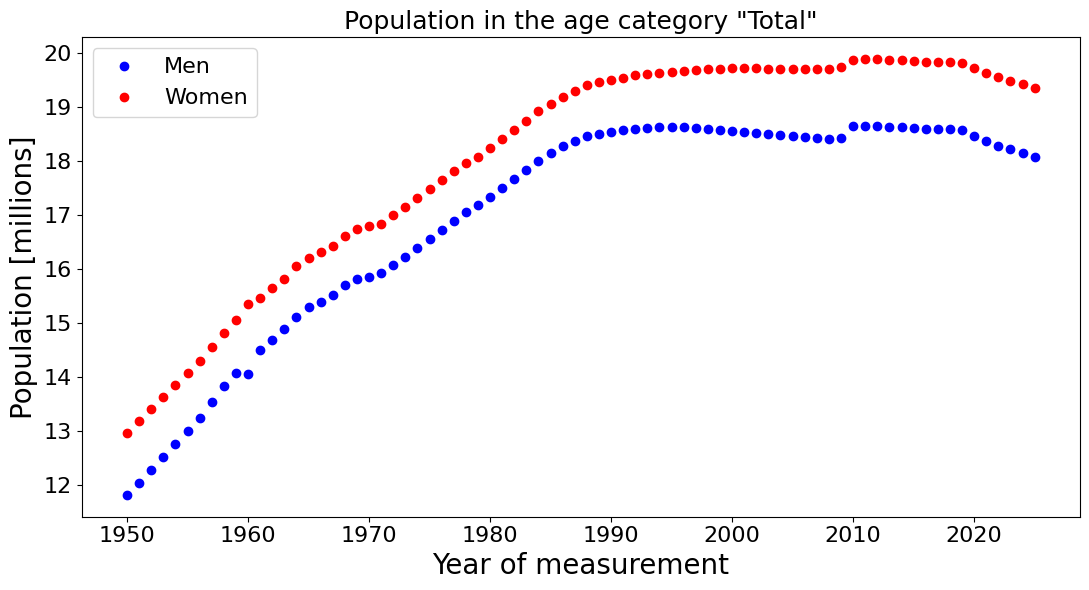

In [3]:
# Select age category for the plot

MyAge = "_T"    
# MyAge = "Y35T39"  # Try to uncomment and see the result. Can you explain it?!

# Flag for selecting age category

inage = hw["AGE"] == MyAge

AgeName = hw["Age"][inage].iat[0]
    
# Flags to select rows with given sex

isman = hw["Sex"] == "Male"
iswom = hw["Sex"] == "Female"

# Extract numpy arrays with years and population count in given age range

nman = hw["OBS_VALUE"][isman * inage].to_numpy()
yman = hw["TIME_PERIOD"][isman * inage].to_numpy()

nwom = hw["OBS_VALUE"][iswom * inage].to_numpy()
ywom = hw["TIME_PERIOD"][iswom * inage].to_numpy()


# Plot population vs year 

plt.figure(figsize=(11, 6))

plt.plot(yman,nman/1e6,'o',label='Men', c = 'blue')
plt.plot(ywom,nwom/1e6,'o',label='Women', c = 'red')

plt.xlabel('Year of measurement',size=20)
plt.ylabel('Population [millions]',size=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.title("Population in the age category \""+AgeName+"\"",size=18)
plt.legend(title='',fontsize=16)

fname = MyAge+'.png'

plt.tight_layout()
plt.savefig(fname)

plt.show()

In this cell I want to better understand the age groups used in the dataset.
First, I create an ordered list of age groups, then I add the "aggregate" variables.\
The 24 variables are shown below.

In [4]:
groups = ["Y_LE4"] + [f"Y{a}T{a+4}" for a in range(5, 85, 5)] + ["Y_GE85"]
labels = ["0-4"] + [f"{a}-{a+4}" for a in range(5, 85, 5)] + ["85+"]
aggregates = ["Y_LT20", "Y15T64", "Y20T64", "Y_GE50", "Y_GE65", "_T"]

cats = (hw[["AGE", "Age"]].drop_duplicates().set_index("AGE")
        .loc[groups + aggregates].reset_index())
cats["type"] = ["5-year group"] * len(groups) + ["aggregate"] * len(aggregates)
print(cats.to_string())


       AGE                  Age          type
0    Y_LE4      4 years or less  5-year group
1     Y5T9    From 5 to 9 years  5-year group
2   Y10T14  From 10 to 14 years  5-year group
3   Y15T19  From 15 to 19 years  5-year group
4   Y20T24  From 20 to 24 years  5-year group
5   Y25T29  From 25 to 29 years  5-year group
6   Y30T34  From 30 to 34 years  5-year group
7   Y35T39  From 35 to 39 years  5-year group
8   Y40T44  From 40 to 44 years  5-year group
9   Y45T49  From 45 to 49 years  5-year group
10  Y50T54  From 50 to 54 years  5-year group
11  Y55T59  From 55 to 59 years  5-year group
12  Y60T64  From 60 to 64 years  5-year group
13  Y65T69  From 65 to 69 years  5-year group
14  Y70T74  From 70 to 74 years  5-year group
15  Y75T79  From 75 to 79 years  5-year group
16  Y80T84  From 80 to 84 years  5-year group
17  Y_GE85     85 years or over  5-year group
18  Y_LT20   Less than 20 years     aggregate
19  Y15T64  From 15 to 64 years     aggregate
20  Y20T64  From 20 to 64 years   

To better understand which age group we are interested in, we can plot the population distribution in 1950. The age group we're interested in is 0–4.\
After five years, the people in this group will have moved on to the next group.\
Below is a graph showing the group of interest to us in four different years: 1950, 1975, 2000, and 2025.\
At this time, we do not distinguish between males and females.

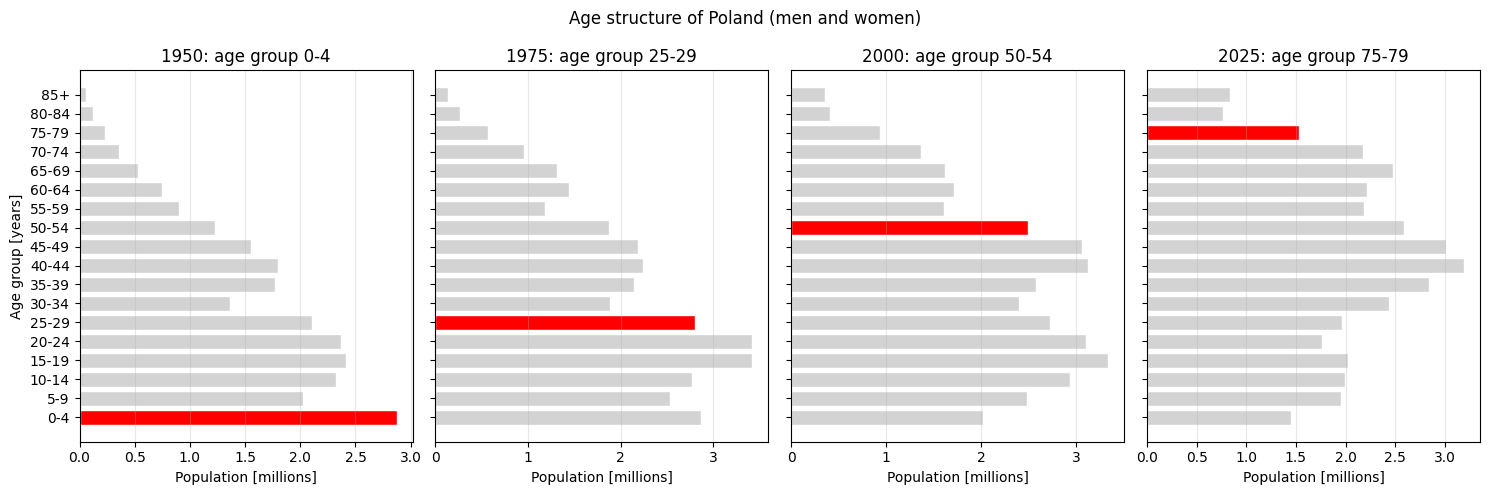

In [21]:
years = [1950, 1975, 2000, 2025]

fig, axes = plt.subplots(1, len(years), figsize=(15, 5), sharey=True)
for ax, year in zip(axes, years):
    pop = (hw[(hw.TIME_PERIOD == year) & hw.AGE.isin(groups)]   #
           .groupby("AGE").OBS_VALUE.sum()[groups] / 1e6)
    k = (year - 1950) // 5

    colors = ["lightgray"] * len(groups)
    colors[k] = "red"
    ax.barh(labels, pop, color=colors, edgecolor="white", linewidth=1)
    ax.set_title(f"{year}: age group {labels[k]}")
    ax.set_xlabel("Population [millions]")
    ax.grid(axis="x", alpha=0.3)
axes[0].set_ylabel("Age group [years]")
fig.suptitle("Age structure of Poland (men and women)")
fig.tight_layout()
fig.savefig("age_structure.png", dpi = 500)
plt.show()

### Task 1 ###
_Prepare the plot showing the population of men and women born in 1946-1950
(not older than 4 in 1950), as a function of year (or age)._

As shown in the previous cell, to create this plot we must consider the population that was 0–4 years old in 1950 and track it over the years through 2025.

    year age_group          M          F
0   1950       0-4  1461961.5  1411228.0
1   1955       5-9  1416045.0  1372292.5
2   1960     10-14  1547047.0  1492965.0
3   1965     15-19  1470800.0  1421300.0
4   1970     20-24  1498807.0  1458565.0
5   1975     25-29  1415026.0  1384379.0
6   1980     30-34  1395701.0  1372676.0
7   1985     35-39  1371361.0  1359932.0
8   1990     40-44  1209059.0  1218442.0
9   1995     45-49  1244809.0  1281691.0
10  2000     50-54  1201828.0  1286469.0
11  2005     55-59  1122211.0  1251972.0
12  2010     60-64  1038241.0  1209910.0
13  2015     65-69   917893.0  1147725.0
14  2020     70-74   773122.0  1055486.0
15  2025     75-79   603409.0   923155.0


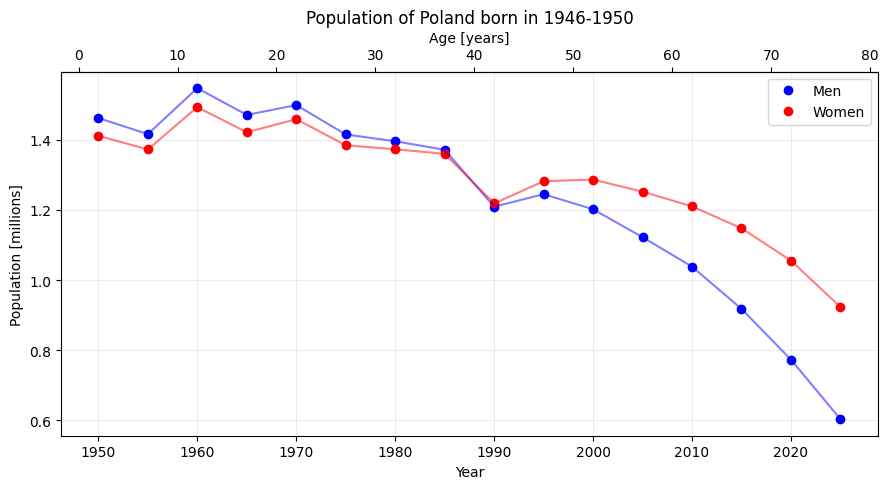

In [22]:
rows = []
for k in range(16): # We only need the first 16 age groups to track this subset of the population
    year = 1950 + 5 * k
    sel = (hw.TIME_PERIOD == year) & (hw.AGE == groups[k])

    # Create a dictionary with the year, age group and population of men and women in that age group
    rows.append({"year": year, "age_group": labels[k],
                 "M": hw.OBS_VALUE[sel & isman].iat[0],
                 "F": hw.OBS_VALUE[sel & iswom].iat[0]})

batch = pd.DataFrame(rows)
print(batch)

fig, ax = plt.subplots(figsize=(9, 5))

# Plot of the population born in 1946-1950 as a function of year
ax.plot(batch.year, batch.M / 1e6, "o", label="Men", c = 'blue')
ax.plot(batch.year, batch.F / 1e6, "o", label="Women", c = 'red')

# I added an interpolation to have a line connecting the points
xx = np.linspace(1950, 2025, 100)
plt.plot(xx, np.interp(xx, batch.year, batch.M / 1e6), "-", c = 'blue', alpha=0.5)
plt.plot(xx, np.interp(xx, batch.year, batch.F / 1e6), "-", c = 'red', alpha=0.5)

ax.set_xlabel("Year")
ax.set_ylabel("Population [millions]")
ax.set_title("Population of Poland born in 1946-1950")
ax.grid(alpha=0.3, c = 'silver')
ax.legend()

# We can add a secondary x axis with the age of the batch
# We consider the age of the batch as the centre of the age group
# the .secondary_xaxis method takes two functions:
# one to convert primary axis values to secondary axis values, and vice versa.

sec = ax.secondary_xaxis("top", functions=(lambda y: y - 1950 + 2, lambda a: a + 1950 - 2))
sec.set_xlabel("Age [years]")


plt.tight_layout()
fig.savefig("task1.png", dpi=300)
plt.show()
